# Mecânica dos Fluidos — Aula 04
## Conceitos Básicos do Movimento dos Fluidos e Análise Tensorial
### Programa de Pós-Graduação em Modelagem Matemática (PPGMMat) — UFPel

Este notebook acompanha e aprofunda os tópicos da **Aula 04** (`aula04.pdf`), transformando a teoria físico-matemática da mecânica dos meios contínuos em experimentos computacionais interativos.

---

### Objetivos e Estrutura do Notebook:
1. **Hipóteses e Notação**: Descrições Euleriana e Lagrangiana do campo de escoamento.
2. **Campo de Velocidades**: Visualização Euleriana (linhas de corrente e vetores) vs. Lagrangiana (trajetórias pontuais).
3. **Derivada Substancial e Aceleração**: Decomposição da aceleração em parcelas local e convectiva.
4. **Cinemática da Rotação e Vorticidade**: Rotação angular média ($\Omega_z$), vorticidade ($\omega_z$) e circulação ($\Gamma$).
5. **ANÁLISE TENSORIAL E SIMULAÇÃO DO MOVIMENTO DA PARTÍCULA FLUIDA**:
   - O Tensor Gradiente de Velocidades $\mathbf{L} = \nabla \mathbf{V}$.
   - Decomposição de Cauchy-Stokes (Teorema de Helmholtz): Tensor de Taxa de Deformação $\mathbf{D}$ e Tensor de Rotação/Spin $\mathbf{\Omega}$.
   - Decomposição didática dos 4 componentes do movimento do elemento fluido (Figura 4.3 da Aula 04: Translação, Rotação de corpo rígido, Deformação linear pura e Deformação angular).
   - O Tensor de Tensões de Cauchy $\boldsymbol{\sigma} = -p\mathbf{I} + 2\mu\mathbf{D}$ e as forças superficiais decorrentes de sua divergência ($\nabla \cdot \boldsymbol{\sigma}$).
   - Simulação Lagrangiana contínua do elemento material deformável integrado via Runge-Kutta 4ª ordem (RK4).
   - Séries temporais de taxas de deformação, rotação, tensões normais e cisalhantes.
   - Animação dinâmica do movimento e distorção da partícula fluida no plano cartesiano.
6. **Pressão em Fluido Estático (Hidrostática)**: Variação de pressão manométrica e absoluta, e o estado de tensão hidrostático ($\boldsymbol{\sigma} = -p\mathbf{I}$).
7. **Tensão de Cisalhamento e Escoamentos Viscosos**: Soluções de Couette e Poiseuille via Lei de Stokes ($\tau_{xy} = 2\mu D_{xy} = \mu \frac{du}{dy}$).
8. **Conservação da Massa**: Equação da continuidade diferencial e a interpretação física de $\nabla \cdot \mathbf{V} = \mathrm{tr}(\mathbf{D}) = 0$.
9. **Quantidade de Movimento (Navier-Stokes e Euler)**: Relação entre o tensor de tensões e aceleração; simulação numérica 1D da difusão viscosa transiente até o perfil permanente.
10. **Síntese Conceitual e Exercícios**: Mapa de relações e questionário analítico com gabarito detalhado.

---
*Convenção: Todas as simulações utilizam o Sistema Internacional de Unidades (SI).*

## 1. Hipóteses, Notação e Modelagem Cinemática

Em mecânica dos fluidos, um escoamento bidimensional no plano cartesiano é descrito no referencial Euleriano pelo campo vetorial de velocidades:
$$
\mathbf{V}(x,y,t) = u(x,y,t)\mathbf{i} + v(x,y,t)\mathbf{j}
$$
- **Descrição Euleriana**: Observamos propriedades de campo (velocidade, aceleração, pressão, tensões) em posições fixas do espaço $(x,y)$ à medida que o tempo avança.
- **Descrição Lagrangiana**: Acompanhamos a trajetória de uma partícula material individual com posição inicial $\mathbf{x}_0 = (x_0, y_0)$ em $t=0$, satisfazendo o problema de valor inicial (PVI):
$$
\frac{d\mathbf{x}}{dt} = \mathbf{V}(\mathbf{x}(t), t), \qquad \mathbf{x}(0) = \mathbf{x}_0
$$
Abaixo implementamos os campos canônicos estudados na Aula 04:
1. **Cisalhamento Simples**: $u(y) = \dot{\gamma} y$, $v = 0$ (típico de escoamento entre placas móveis).
2. **Escoamento Não Permanente Oscilatório**: $u(t) = 1 + 0{,}5\sin(t)$, $v(x) = 0{,}4 x$.
3. **Escoamento Extensional Puro / Ponto de Estagnação**: $u(x) = k x$, $v(y) = -k y$ (escoamento irrotacional e incompressível).
4. **Vórtice Regularizado (Rankine / Lamb-Oseen Suave)**:
$$
u(x,y) = -\frac{\Gamma y}{x^2+y^2+r_0^2}, \qquad v(x,y) = \frac{\Gamma x}{x^2+y^2+r_0^2}
$$

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import polar
from IPython.display import HTML, Image, display

# Configurações visuais elegantes para gráficos acadêmicos
plt.rcParams.update({
    "figure.figsize": (8.5, 5.0),
    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.6,
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "legend.fontsize": 10,
    "figure.autolayout": True
})
np.set_printoptions(precision=4, suppress=True)

# 1. Definição dos campos de velocidade bidimensionais
def campo_cisalhamento(x, y, t=0, gamma_dot=1.2):
    # Cisalhamento simples puro: u = gamma_dot * y, v = 0
    return gamma_dot * y, np.zeros_like(y)

def campo_nao_permanente(x, y, t):
    # Escoamento não permanente com aceleração local e convectiva simultâneas
    u = 1.0 + 0.5 * np.sin(t) + 0.0 * x
    v = 0.4 * x + 0.0 * y
    return u, v

def campo_estagnacao(x, y, t=0, k=0.8):
    # Escoamento extensional puro / ponto de estagnação: u = k*x, v = -k*y
    return k * x, -k * y

def campo_vortice(x, y, t=0, Gamma=4.0, r0=0.5):
    # Vórtice suave regularizado no núcleo: sem singularidade em r=0
    r2 = x*x + y*y + r0*r0
    return -Gamma * y / r2, Gamma * x / r2

# 2. Funções utilitárias de malha e integração temporal por Runge-Kutta 4ª Ordem (RK4)
def gerar_grade(campo, lim_x=(-2, 2), lim_y=(-2, 2), n=35, t=0):
    # Gera grade bidimensional e avalia o campo vetorial
    x = np.linspace(lim_x[0], lim_x[1], n)
    y = np.linspace(lim_y[0], lim_y[1], n)
    X, Y = np.meshgrid(x, y)
    U, V = campo(X, Y, t)
    return X, Y, U, V

def integrar_trajetorias_rk4(campo, sementes, t_max=2.5, dt=0.01):
    # Integra trajetórias Lagrangianas via RK4 com alta precisão temporal
    passos = int(t_max / dt)
    t = np.linspace(0, t_max, passos + 1)
    p = np.array(sementes, dtype=float)
    num_part = p.shape[0]
    historico = np.zeros((passos + 1, num_part, 2))
    historico[0] = p.copy()
    
    for n in range(passos):
        tn = t[n]
        pn = historico[n]
        # k1
        u1, v1 = campo(pn[:, 0], pn[:, 1], tn)
        k1 = np.c_[u1, v1]
        # k2
        p2 = pn + 0.5 * dt * k1
        u2, v2 = campo(p2[:, 0], p2[:, 1], tn + 0.5 * dt)
        k2 = np.c_[u2, v2]
        # k3
        p3 = pn + 0.5 * dt * k2
        u3, v3 = campo(p3[:, 0], p3[:, 1], tn + 0.5 * dt)
        k3 = np.c_[u3, v3]
        # k4
        p4 = pn + dt * k3
        u4, v4 = campo(p4[:, 0], p4[:, 1], tn + dt)
        k4 = np.c_[u4, v4]
        
        historico[n + 1] = pn + (dt / 6.0) * (k1 + 2*k2 + 2*k3 + k4)
        
    return t, historico

print("Módulos básicos e campos cinemáticos carregados com sucesso.")

Módulos básicos e campos cinemáticos carregados com sucesso.


## 2. Campo de Velocidades: Perspectivas Euleriana e Lagrangiana

- **Abordagem Euleriana**: O campo vetorial instantâneo é representado por setas (quiver) e linhas de corrente (*streamlines*), as quais são tangentes ao vetor velocidade em cada ponto:
$$
\frac{dx}{u} = \frac{dy}{v}
$$
- **Abordagem Lagrangiana**: Acompanha a evolução das partículas materiais ao longo do tempo.
- **Teorema Fundamental**: Em escoamento **permanente** ($\partial\mathbf{V}/\partial t = 0$), linhas de corrente, trajetórias e linhas de emissão coincidem perfeitamente. Em escoamento **não permanente**, elas diferem substancialmente.

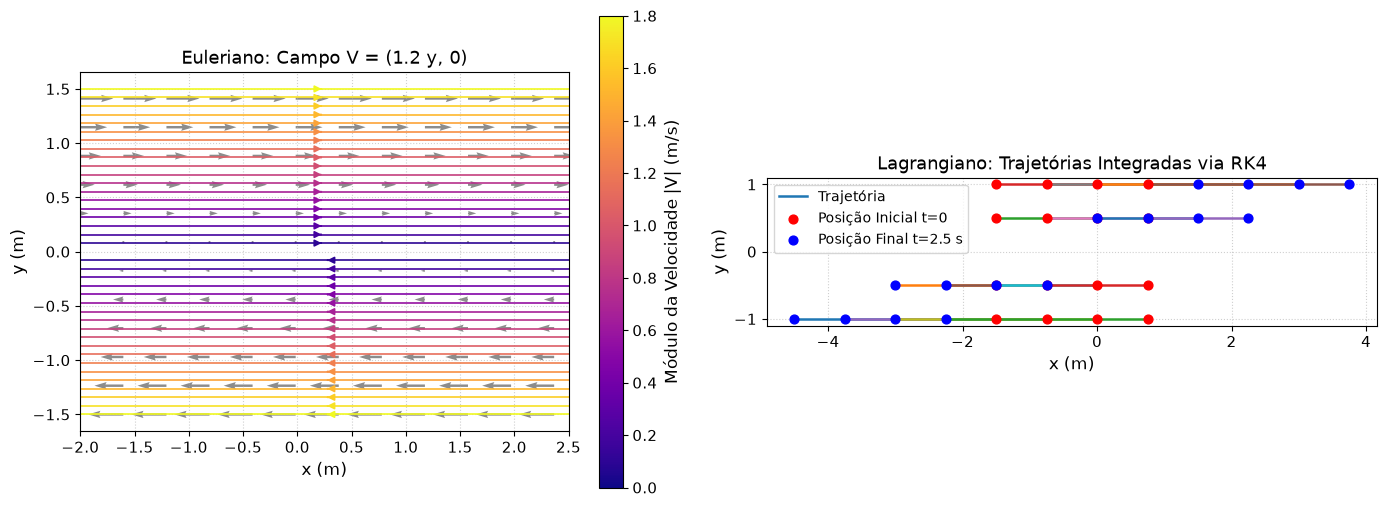

In [2]:
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2))

# Subplot 1: Visão Euleriana (Streamlines + Quiver)
X, Y, U, V = gerar_grade(campo_cisalhamento, lim_x=(-2, 2.5), lim_y=(-1.5, 1.5))
speed = np.hypot(U, V)
st = axs[0].streamplot(X, Y, U, V, color=speed, cmap="plasma", density=1.3, linewidth=1.2)
axs[0].quiver(X[::3, ::3], Y[::3, ::3], U[::3, ::3], V[::3, ::3], color="black", alpha=0.45, scale=25)
fig.colorbar(st.lines, ax=axs[0], label="Módulo da Velocidade |V| (m/s)")
axs[0].set(xlabel="x (m)", ylabel="y (m)", title="Euleriano: Campo V = (1.2 y, 0)")
axs[0].set_aspect("equal")

# Subplot 2: Visão Lagrangiana (Trajetórias integradas)
sementes = [(x, y) for x in [-1.5, -0.75, 0.0, 0.75] for y in [-1.0, -0.5, 0.5, 1.0]]
t_trajet, tr = integrar_trajetorias_rk4(campo_cisalhamento, sementes, t_max=2.5, dt=0.01)

for k in range(tr.shape[1]):
    axs[1].plot(tr[:, k, 0], tr[:, k, 1], lw=1.8, label="Trajetória" if k == 0 else "")
axs[1].scatter(tr[0, :, 0], tr[0, :, 1], color="red", s=40, zorder=5, label="Posição Inicial t=0")
axs[1].scatter(tr[-1, :, 0], tr[-1, :, 1], color="blue", s=40, zorder=5, label="Posição Final t=2.5 s")
axs[1].set(xlabel="x (m)", ylabel="y (m)", title="Lagrangiano: Trajetórias Integradas via RK4")
axs[1].set_aspect("equal")
axs[1].legend(loc="upper left")

plt.show()

## 3. Derivada Substancial e Aceleração

A taxa de variação de uma propriedade $\phi$ ao acompanhar uma partícula fluida é a **derivada substancial** (ou material):
$$
\frac{D\phi}{Dt} = \frac{\partial\phi}{\partial t} + (\mathbf{V}\cdot\nabla)\phi
$$
Aplicando ao vetor velocidade $\mathbf{V}$, obtemos a aceleração total da partícula fluida:
$$
\mathbf{a} = \frac{D\mathbf{V}}{Dt} = \underbrace{\frac{\partial\mathbf{V}}{\partial t}}_{\text{Aceleração Local}} + \underbrace{(\mathbf{V}\cdot\nabla)\mathbf{V}}_{\text{Aceleração Convectiva}}
$$
Em coordenadas cartesianas 2D:
$$
a_x = \frac{\partial u}{\partial t} + u\frac{\partial u}{\partial x} + v\frac{\partial u}{\partial y}, \qquad
a_y = \frac{\partial v}{\partial t} + u\frac{\partial v}{\partial x} + v\frac{\partial v}{\partial y}
$$
- A **aceleração local** deve-se à não-permanência temporal no ponto fixo.
- A **aceleração convectiva** deve-se à variação espacial da velocidade experimentada pela partícula ao transladar de um ponto a outro no campo de escoamento.

ANÁLISE DA DERIVADA SUBSTANCIAL NO PONTO P(1.0, 0.5) para t = 0.7 s
Aceleração Local      ∂V/∂t     = [  0.3824,   0.0000] m/s²
Aceleração Convectiva (V·∇)V    = [  0.0000,   0.5288] m/s²
Aceleração Total      DV/Dt     = [  0.3824,   0.5288] m/s²


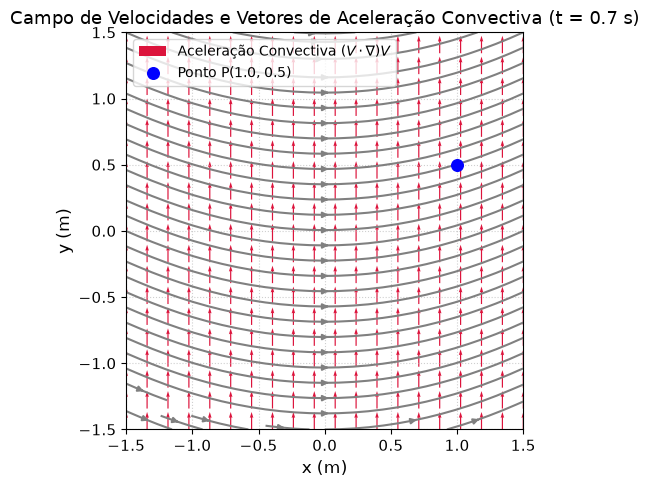

In [3]:
def aceleracao_substancial(campo, x, y, t, h=1e-5):
    # Calcula numericamente as componentes de aceleração local, convectiva e substancial total
    x, y = float(x), float(y)
    u0, v0 = campo(x, y, t)
    
    # 1. Aceleração local: derivada temporal parcial dV/dt
    ut_p, vt_p = campo(x, y, t + h)
    ut_m, vt_m = campo(x, y, t - h)
    a_local = np.array([(ut_p - ut_m) / (2 * h), (vt_p - vt_m) / (2 * h)])
    
    # 2. Gradientes espaciais para aceleração convectiva: (V . grad) V
    ux_p, vx_p = campo(x + h, y, t); ux_m, vx_m = campo(x - h, y, t)
    uy_p, vy_p = campo(x, y + h, t); uy_m, vy_m = campo(x, y - h, t)
    dudx = (ux_p - ux_m) / (2 * h); dudy = (uy_p - uy_m) / (2 * h)
    dvdx = (vx_p - vx_m) / (2 * h); dvdy = (vy_p - vy_m) / (2 * h)
    
    a_conv_x = u0 * dudx + v0 * dudy
    a_conv_y = u0 * dvdx + v0 * dvdy
    a_convectiva = np.array([a_conv_x, a_conv_y])
    a_total = a_local + a_convectiva
    
    return a_local, a_convectiva, a_total

x_p, y_p, t_p = 1.0, 0.5, 0.7
a_loc, a_cnv, a_tot = aceleracao_substancial(campo_nao_permanente, x_p, y_p, t_p)

print("=" * 65)
print(f"ANÁLISE DA DERIVADA SUBSTANCIAL NO PONTO P({x_p}, {y_p}) para t = {t_p} s")
print("=" * 65)
print(f"Aceleração Local      ∂V/∂t     = [{a_loc[0]:8.4f}, {a_loc[1]:8.4f}] m/s²")
print(f"Aceleração Convectiva (V·∇)V    = [{a_cnv[0]:8.4f}, {a_cnv[1]:8.4f}] m/s²")
print(f"Aceleração Total      DV/Dt     = [{a_tot[0]:8.4f}, {a_tot[1]:8.4f}] m/s²")
print("=" * 65)

# Visualização da aceleração convectiva sobre o campo vetorial
X, Y, U, V = gerar_grade(campo_nao_permanente, lim_x=(-1.5, 1.5), lim_y=(-1.5, 1.5), n=20, t=t_p)
Ax = np.zeros_like(X)
Ay = np.zeros_like(Y)
for i in range(X.shape[0]):
    for j in range(X.shape[1]):
        _, a_c, _ = aceleracao_substancial(campo_nao_permanente, X[i, j], Y[i, j], t_p)
        Ax[i, j], Ay[i, j] = a_c[0], a_c[1]

fig, ax = plt.subplots(figsize=(7.5, 5))
st = ax.streamplot(X, Y, U, V, color="gray", density=0.9, arrowsize=0.8)
qv = ax.quiver(X, Y, Ax, Ay, color="crimson", scale=12, label="Aceleração Convectiva $(V\\cdot\\nabla)V$")
ax.scatter([x_p], [y_p], color="blue", s=70, zorder=6, label=f"Ponto P({x_p}, {y_p})")
ax.set(xlabel="x (m)", ylabel="y (m)", title=f"Campo de Velocidades e Vetores de Aceleração Convectiva (t = {t_p} s)")
ax.set_aspect("equal")
ax.legend(loc="upper left")
plt.show()

## 4. Rotação, Vorticidade e Circulação

Na cinemática clássica (Seção 3 da Aula 04), a velocidade angular média de rotação em torno do eixo $z$ de duas linhas materiais perpendiculares que se cruzam na partícula fluida é:
$$
\Omega_z = \frac{1}{2}\left(\frac{\partial v}{\partial x} - \frac{\partial u}{\partial y}\right)
$$
A **vorticidade** é o dobro da velocidade angular média:
$$
\omega_z = (\nabla \times \mathbf{V})_z = \frac{\partial v}{\partial x} - \frac{\partial u}{\partial y} = 2\Omega_z
$$
A **circulação** $\Gamma$ ao longo de um contorno fechado $C$ mede a rotação macroscópica líquida:
$$
\Gamma = \oint_C \mathbf{V}\cdot d\mathbf{s} = \iint_A (\nabla\times\mathbf{V})_z \, dA = \iint_A \omega_z \, dA \quad \text{(Teorema de Stokes)}
$$
- Em cisalhamento simples $\mathbf{V}=(1{,}2 y, 0)$, a vorticidade é uniforme: $\omega_z = -1{,}2\text{ s}^{-1}$.
- No vórtice suave, a vorticidade concentra-se no núcleo e decai suavemente com o raio.

Circulação em r = 1.0 m (Cisalhamento simples): -3.7699 m²/s  (analítico: -3.7699 m²/s)
Circulação em r = 1.0 m (Vórtice regularizado): 20.1062 m²/s  (analítico: 20.1062 m²/s)


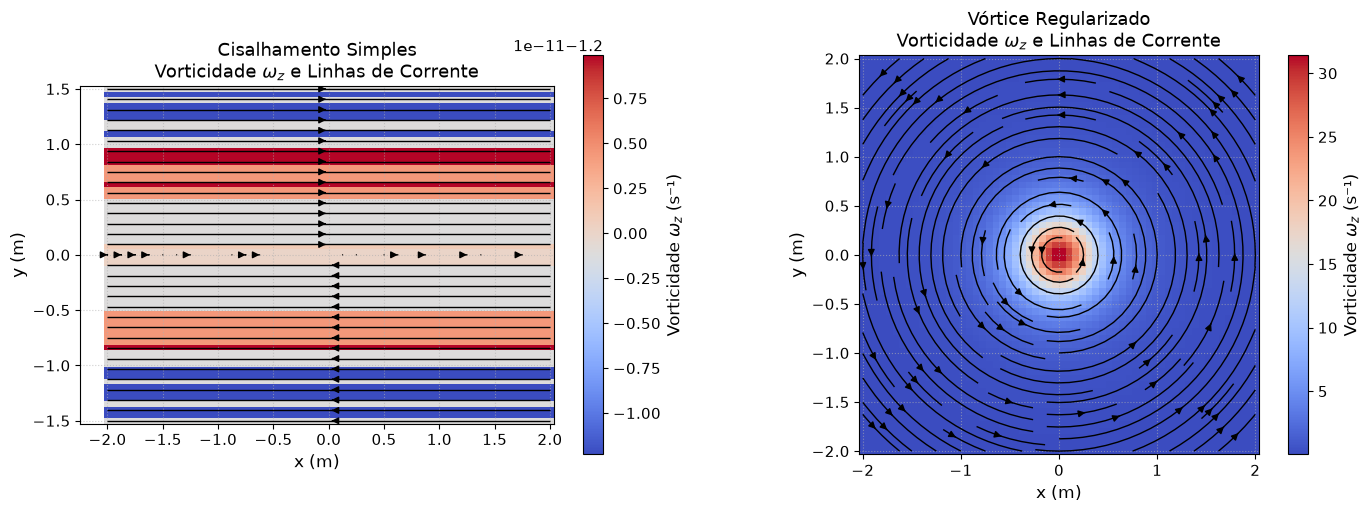

In [4]:
def calcular_vorticidade(campo, X, Y, t=0, h=1e-5):
    # Calcula a componente normal da vorticidade: omega_z = dv/dx - du/dy
    Uxp, Vxp = campo(X + h, Y, t); Uxm, Vxm = campo(X - h, Y, t)
    Uyp, Vyp = campo(X, Y + h, t); Uym, Vym = campo(X, Y - h, t)
    dvdx = (Vxp - Vxm) / (2 * h)
    dudy = (Uyp - Uym) / (2 * h)
    return dvdx - dudy

def calcular_circulacao(campo, raio=1.0, centro=(0.0, 0.0), n_pontos=2000, t=0):
    # Calcula a circulação fechada Gamma = integral V . ds por quadratura numérica
    theta = np.linspace(0, 2 * np.pi, n_pontos, endpoint=False)
    d_theta = 2 * np.pi / n_pontos
    x = centro[0] + raio * np.cos(theta)
    y = centro[1] + raio * np.sin(theta)
    u, v = campo(x, y, t)
    dx = -raio * np.sin(theta) * d_theta
    dy =  raio * np.cos(theta) * d_theta
    return np.sum(u * dx + v * dy)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.2))
casos = [
    (axs[0], campo_cisalhamento, "Cisalhamento Simples", (-2, 2), (-1.5, 1.5)),
    (axs[1], campo_vortice, "Vórtice Regularizado", (-2, 2), (-2, 2))
]

for ax, campo, titulo, lx, ly in casos:
    X, Y, U, V = gerar_grade(campo, lim_x=lx, lim_y=ly, n=60)
    omega = calcular_vorticidade(campo, X, Y)
    im = ax.pcolormesh(X, Y, omega, shading="auto", cmap="coolwarm")
    ax.streamplot(X, Y, U, V, color="black", density=1.1, linewidth=1.0)
    ax.set_aspect("equal")
    ax.set(xlabel="x (m)", ylabel="y (m)", title=f"{titulo}\nVorticidade $\\omega_z$ e Linhas de Corrente")
    fig.colorbar(im, ax=ax, label="Vorticidade $\\omega_z$ (s⁻¹)")

plt.show()

circ_cis = calcular_circulacao(campo_cisalhamento, raio=1.0)
circ_vor = calcular_circulacao(campo_vortice, raio=1.0)
print(f"Circulação em r = 1.0 m (Cisalhamento simples): {circ_cis:.4f} m²/s  (analítico: {-np.pi*1.2:.4f} m²/s)")
print(f"Circulação em r = 1.0 m (Vórtice regularizado): {circ_vor:.4f} m²/s  (analítico: {4.0*2*np.pi*1.0/(1.0+0.25):.4f} m²/s)")

## 5. Análise Tensorial e Simulação do Movimento da Partícula Fluida

### 5.1 O Tensor Gradiente de Velocidades e a Decomposição de Cauchy-Stokes
Uma partícula de fluido **não é um ponto adimensional rígido**, mas um elemento material infinitesimal contínuo (volume de controle diferencial).
Considerando uma vizinhança de uma partícula centrada em $\mathbf{x}$, o gradiente de velocidade no referencial cartesiano define o **Tensor de Segunda Ordem Gradiente de Velocidades**:
$$
\mathbf{L} = \nabla \mathbf{V} = \begin{bmatrix} \frac{\partial u}{\partial x} & \frac{\partial u}{\partial y} \\ \frac{\partial v}{\partial x} & \frac{\partial v}{\partial y} \end{bmatrix}
$$
Pelo **Teorema de Helmholtz e Decomposição de Cauchy-Stokes**, qualquer tensor de segunda ordem divide-se de forma única na soma de um tensor simétrico e um tensor antissimétrico:
$$
\mathbf{L} = \mathbf{D} + \mathbf{\Omega}
$$

1. **Tensor de Taxa de Deformação $\mathbf{D}$ (Simétrico)**:
$$
\mathbf{D} = \frac{1}{2}(\mathbf{L} + \mathbf{L}^T) = \begin{bmatrix} D_{xx} & D_{xy} \\ D_{yx} & D_{yy} \end{bmatrix} = \begin{bmatrix} \frac{\partial u}{\partial x} & \frac{1}{2}\left(\frac{\partial u}{\partial y} + \frac{\partial v}{\partial x}\right) \\ \frac{1}{2}\left(\frac{\partial u}{\partial y} + \frac{\partial v}{\partial x}\right) & \frac{\partial v}{\partial y} \end{bmatrix}
$$
   - **Termos Diagonais ($D_{xx}, D_{yy}$)**: Taxas de **deformação linear** (alongamento ou encurtamento nas direções dos eixos coordenados).
   - **Termos Fora da Diagonal ($D_{xy} = D_{yx}$)**: Metade da **taxa de deformação angular** (cisalhamento mútuo puro $\dot{\gamma}_{xy} = 2 D_{xy}$).
   - **Traço de $\mathbf{D}$**: Taxa de **dilatação volumétrica relativa**:
$$
\mathrm{tr}(\mathbf{D}) = D_{xx} + D_{yy} = \nabla\cdot\mathbf{V}
$$
   Para fluido incompressível, $\mathrm{tr}(\mathbf{D}) = 0$.

2. **Tensor de Rotação / Spin $\mathbf{\Omega}$ (Antissimétrico)**:
$$
\mathbf{\Omega} = \frac{1}{2}(\mathbf{L} - \mathbf{L}^T) = \begin{bmatrix} 0 & -\Omega_z \\ \Omega_z & 0 \end{bmatrix} = \begin{bmatrix} 0 & -\frac{1}{2}\omega_z \\ \frac{1}{2}\omega_z & 0 \end{bmatrix}
$$
   Representa a **rotação de corpo rígido instantânea** da partícula com velocidade angular $\Omega_z = \frac{1}{2}\omega_z$.

---

### 5.2 O Tensor de Tensões de Cauchy $\boldsymbol{\sigma}$ e as Forças Superficiais
Na Seção 5 e 11 da Aula 04, a ação mecânica entre partículas vizinhas é quantificada pelo **Tensor de Tensões de Cauchy** $\boldsymbol{\sigma}$. Para um fluido newtoniano incompressível:
$$
\boldsymbol{\sigma} = -p\mathbf{I} + \boldsymbol{\tau} = -p\mathbf{I} + 2\mu\mathbf{D} = \begin{bmatrix} -p + 2\mu \frac{\partial u}{\partial x} & \mu\left(\frac{\partial u}{\partial y} + \frac{\partial v}{\partial x}\right) \\ \mu\left(\frac{\partial u}{\partial y} + \frac{\partial v}{\partial x}\right) & -p + 2\mu \frac{\partial v}{\partial y} \end{bmatrix}
$$
Pela 2ª Lei de Newton aplicada ao elemento de fluido de massa $dm = \rho d\forall$:
$$
\rho \frac{D\mathbf{V}}{Dt} = \nabla \cdot \boldsymbol{\sigma} + \rho\mathbf{g} = -\nabla p + \mu\nabla^2\mathbf{V} + \rho\mathbf{g}
$$
A força líquida superficial que acelera a partícula de fluido advém rigorosamente da divergência do tensor de tensões.

---

### 5.3 Cinemática do Elemento Material (Partícula Real Deformável)
Seja um elemento de fluido com centroide $\mathbf{x}_c(t)$ e contorno de pontos materiais $\mathbf{x}(t) = \mathbf{x}_c(t) + \delta\mathbf{x}(t)$. A evolução cinemática do elemento material satisfaz:
$$
\frac{d\mathbf{x}_c}{dt} = \mathbf{V}(\mathbf{x}_c, t) \qquad \text{(Translação)}
$$
$$
\frac{d\mathbf{F}}{dt} = \mathbf{L}(\mathbf{x}_c, t)\mathbf{F}(t), \quad \mathbf{F}(0) = \mathbf{I} \qquad \text{(Deformação e Rotação)}
$$
Onde $\mathbf{F}(t)$ é o **Tensor Gradiente de Deformação**. Qualquer vetor material inicial $\delta\mathbf{X}_0$ evolui como:
$$
\delta\mathbf{x}(t) = \mathbf{F}(t)\delta\mathbf{X}_0
$$
Pela **decomposição polar** $\mathbf{F}(t) = \mathbf{R}(t)\mathbf{U}(t)$, separamos exatamente:
- $\mathbf{R}(t)$: O **Tensor de Rotação Rígida Finita** (ângulo $\theta_{\text{rot}}(t)$).
- $\mathbf{U}(t)$: O **Tensor de Estiramento Puro** (alongamento nas direções principais $\lambda_1, \lambda_2$).
- A distorção angular entre dois eixos materiais inicialmente ortogonais é:
$$
\gamma(t) = 90^\circ - \arccos\left(\frac{\mathbf{e}_x(t)\cdot\mathbf{e}_y(t)}{\|\mathbf{e}_x(t)\|\|\mathbf{e}_y(t)\|}\right)
$$

In [5]:
def calcular_tensores(campo, x, y, t=0, mu=1e-3, p=101325, h=1e-5):
    # Calcula todos os tensores mecânicos no ponto (x,y): L, D, Omega, tau, sigma
    x, y = float(x), float(y)
    uxp, vxp = campo(x + h, y, t); uxm, vxm = campo(x - h, y, t)
    uyp, vyp = campo(x, y + h, t); uym, vym = campo(x, y - h, t)
    
    dudx = (uxp - uxm) / (2 * h); dudy = (uyp - uym) / (2 * h)
    dvdx = (vxp - vxm) / (2 * h); dvdy = (vyp - vym) / (2 * h)
    
    L = np.array([[dudx, dudy],
                  [dvdx, dvdy]])
    D = 0.5 * (L + L.T)
    Omega = 0.5 * (L - L.T)
    tau = 2.0 * mu * D
    sigma = -p * np.eye(2) + tau
    
    omega_z = dvdx - dudy
    Omega_z = 0.5 * omega_z
    taxa_cisalhamento = 2.0 * D[0, 1]
    
    eigvals, eigvecs = np.linalg.eigh(sigma)
    tau_max = 0.5 * (eigvals[1] - eigvals[0])
    
    return {
        "L": L, "D": D, "Omega": Omega, "tau": tau, "sigma": sigma,
        "omega_z": omega_z, "Omega_z": Omega_z, "gamma_dot": taxa_cisalhamento,
        "div_V": np.trace(D), "eigvals": eigvals, "eigvecs": eigvecs, "tau_max": tau_max
    }

# Exemplo numérico de verificação no campo de cisalhamento
res = calcular_tensores(campo_cisalhamento, x=1.0, y=0.5, mu=1e-3, p=101325)

print("=" * 70)
print("AVALIAÇÃO DO ESTADO TENSORIAL NO PONTO (x=1.0 m, y=0.5 m)")
print("=" * 70)
print("1. Tensor Gradiente de Velocidades L = ∇V (s⁻¹):")
print(res["L"])
print("\n2. Tensor de Taxa de Deformação D (s⁻¹):")
print(res["D"])
print(f"   -> Taxas lineares: D_xx = {res['D'][0,0]:.4f} s⁻¹, D_yy = {res['D'][1,1]:.4f} s⁻¹")
print(f"   -> Taxa de cisalhamento angular pura: gamma_dot = {res['gamma_dot']:.4f} s⁻¹")
print(f"   -> Taxa de dilatação volumétrica: tr(D) = div(V) = {res['div_V']:.4e} s⁻¹")
print("\n3. Tensor de Rotação / Spin Ω (rad/s):")
print(res["Omega"])
print(f"   -> Velocidade angular rígida: Ω_z = {res['Omega_z']:.4f} rad/s")
print(f"   -> Vorticidade: ω_z = {res['omega_z']:.4f} s⁻¹")
print("\n4. Tensor de Tensões Viscosas τ = 2μD (Pa):")
print(res["tau"])
print("\n5. Tensor de Tensões de Cauchy σ = -pI + τ (Pa):")
print(res["sigma"])
print(f"   -> Tensão de cisalhamento máxima (Tresca): tau_max = {res['tau_max']:.6f} Pa")
print("=" * 70)

AVALIAÇÃO DO ESTADO TENSORIAL NO PONTO (x=1.0 m, y=0.5 m)
1. Tensor Gradiente de Velocidades L = ∇V (s⁻¹):
[[0.  1.2]
 [0.  0. ]]

2. Tensor de Taxa de Deformação D (s⁻¹):
[[0.  0.6]
 [0.6 0. ]]
   -> Taxas lineares: D_xx = 0.0000 s⁻¹, D_yy = 0.0000 s⁻¹
   -> Taxa de cisalhamento angular pura: gamma_dot = 1.2000 s⁻¹
   -> Taxa de dilatação volumétrica: tr(D) = div(V) = 0.0000e+00 s⁻¹

3. Tensor de Rotação / Spin Ω (rad/s):
[[ 0.   0.6]
 [-0.6  0. ]]
   -> Velocidade angular rígida: Ω_z = -0.6000 rad/s
   -> Vorticidade: ω_z = -1.2000 s⁻¹

4. Tensor de Tensões Viscosas τ = 2μD (Pa):
[[0.     0.0012]
 [0.0012 0.    ]]

5. Tensor de Tensões de Cauchy σ = -pI + τ (Pa):
[[-101325.           0.0012]
 [      0.0012 -101325.    ]]
   -> Tensão de cisalhamento máxima (Tresca): tau_max = 0.001200 Pa


### 5.4 Decomposição dos 4 Componentes do Movimento (Figura 4.3 da Aula 04)

Na Figura 4.3 da Aula 04 (*Componentes do movimento de um elemento de fluido*), o movimento infinitesimal de uma partícula de fluido decompõe-se exatamente em quatro ações cinemáticas fundamentais:
1. **Translação pura**: Deslocamento rígido da partícula pelo vetor velocidade $\mathbf{V}\Delta t$.
2. **Rotação de corpo rígido**: Rotação angular em torno do centro com velocidade $\Omega_z$, preservando as distâncias internas e os ângulos retos de 90° entre os eixos materiais.
3. **Deformação linear pura**: Alongamento ou contração nas direções axiais através das componentes diagonais $D_{xx}, D_{yy}$, preservando a ortogonalidade dos eixos.
4. **Deformação angular (cisalhamento puro)**: Distorção dos ângulos entre as faces materiais pelas componentes fora da diagonal $D_{xy}$.

Abaixo visualizamos lado a lado como cada tensor afeta isoladamente um elemento quadrado inicial com eixos ortogonais materiais $oa$ (vermelho) e $ob$ (verde):

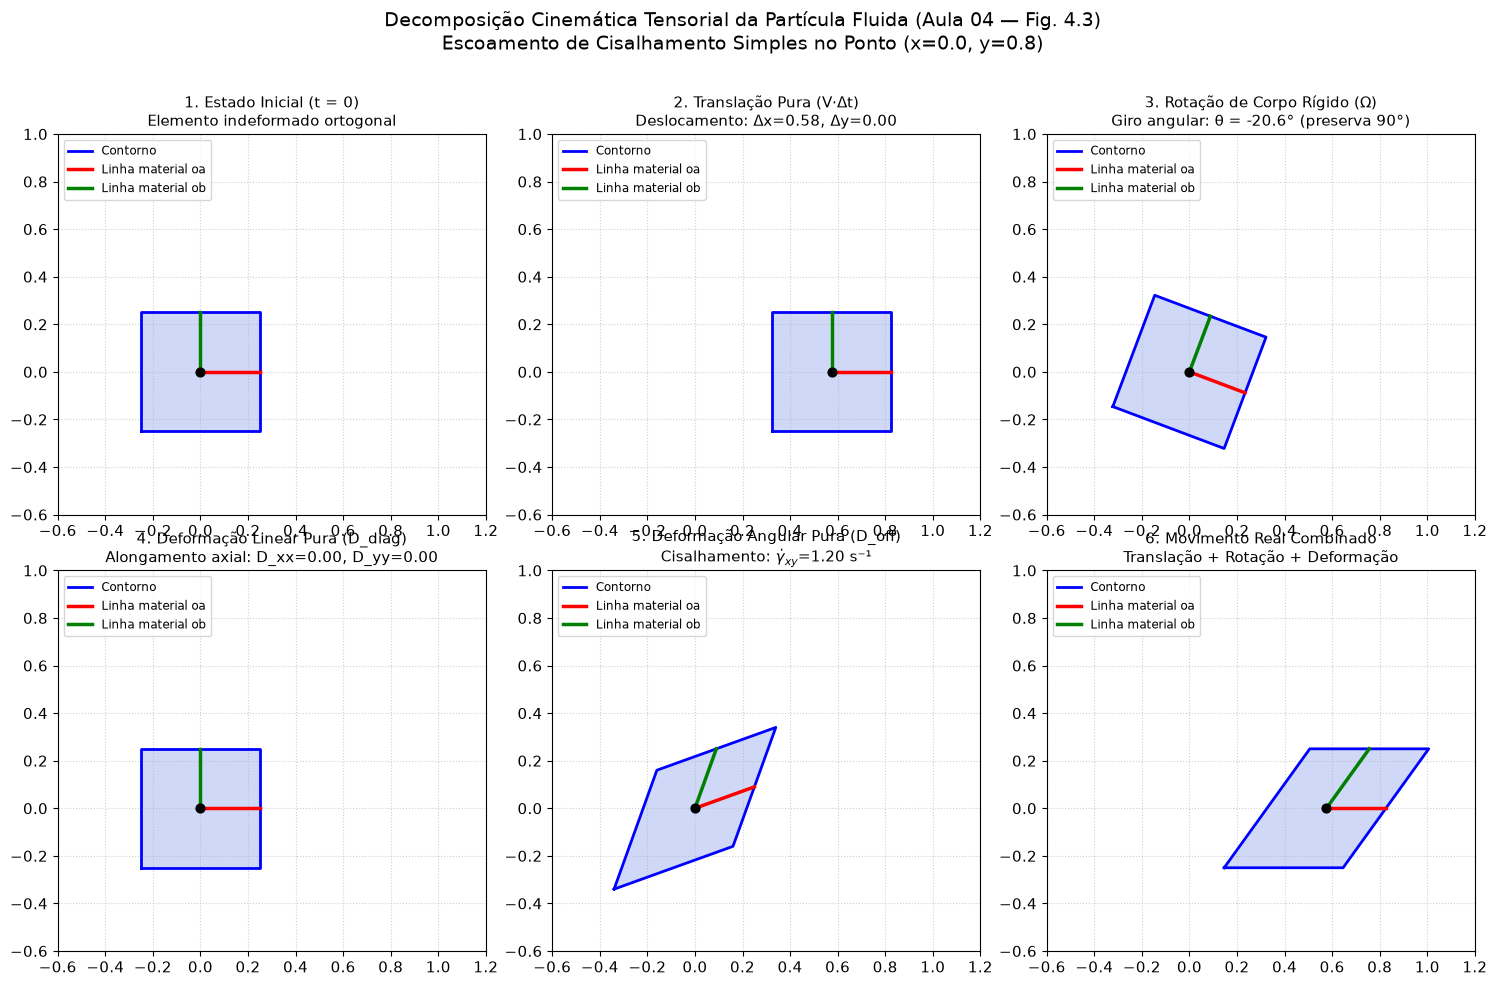

In [6]:
def plot_decomposicao_elemento(campo, x0=0.0, y0=0.8, delta_t=0.6, s=0.25):
    # Gera visualização gráfica didática da decomposição dos 4 componentes do movimento
    res = calcular_tensores(campo, x0, y0)
    L = res["L"]
    D = res["D"]
    Omega = res["Omega"]
    u0, v0 = campo(x0, y0)
    V_desloc = np.array([u0, v0]) * delta_t
    
    # Geometria original do elemento centrado na origem
    quad_0 = np.array([[-s, -s], [s, -s], [s, s], [-s, s], [-s, -s]])
    eixo_a_0 = np.array([[0, 0], [s, 0]])   # linha material oa
    eixo_b_0 = np.array([[0, 0], [0, s]])   # linha material ob
    
    # 1. Translação pura
    quad_trans = quad_0 + V_desloc
    ea_trans = eixo_a_0 + V_desloc
    eb_trans = eixo_b_0 + V_desloc
    
    # 2. Rotação rígida pura: R = exp(Omega * dt)
    theta_rot = res["Omega_z"] * delta_t
    R = np.array([[np.cos(theta_rot), -np.sin(theta_rot)],
                  [np.sin(theta_rot),  np.cos(theta_rot)]])
    quad_rot = quad_0 @ R.T
    ea_rot = eixo_a_0 @ R.T
    eb_rot = eixo_b_0 @ R.T
    
    # 3. Deformação linear pura: D_diag
    F_lin = np.eye(2) + np.diag(np.diag(D)) * delta_t
    quad_lin = quad_0 @ F_lin.T
    ea_lin = eixo_a_0 @ F_lin.T
    eb_lin = eixo_b_0 @ F_lin.T
    
    # 4. Deformação angular pura: D_offdiag
    D_off = np.array([[0.0, D[0, 1]], [D[1, 0], 0.0]])
    F_ang = np.eye(2) + D_off * delta_t
    quad_ang = quad_0 @ F_ang.T
    ea_ang = eixo_a_0 @ F_ang.T
    eb_ang = eixo_b_0 @ F_ang.T
    
    # 5. Movimento Real Combinado: I + L * dt
    F_total = np.eye(2) + L * delta_t
    quad_total = quad_0 @ F_total.T + V_desloc
    ea_total = eixo_a_0 @ F_total.T + V_desloc
    eb_total = eixo_b_0 @ F_total.T + V_desloc
    
    fig, axs = plt.subplots(2, 3, figsize=(15, 9.5))
    painéis = [
        (axs[0, 0], quad_0, eixo_a_0, eixo_b_0, [0, 0], "1. Estado Inicial (t = 0)", "Elemento indeformado ortogonal"),
        (axs[0, 1], quad_trans, ea_trans, eb_trans, V_desloc, "2. Translação Pura (V·Δt)", f"Deslocamento: Δx={V_desloc[0]:.2f}, Δy={V_desloc[1]:.2f}"),
        (axs[0, 2], quad_rot, ea_rot, eb_rot, [0, 0], "3. Rotação de Corpo Rígido (Ω)", f"Giro angular: θ = {np.degrees(theta_rot):.1f}° (preserva 90°)"),
        (axs[1, 0], quad_lin, ea_lin, eb_lin, [0, 0], "4. Deformação Linear Pura (D_diag)", f"Alongamento axial: D_xx={D[0,0]:.2f}, D_yy={D[1,1]:.2f}"),
        (axs[1, 1], quad_ang, ea_ang, eb_ang, [0, 0], "5. Deformação Angular Pura (D_off)", f"Cisalhamento: $\dot{{\gamma}}_{{xy}}$={res['gamma_dot']:.2f} s⁻¹"),
        (axs[1, 2], quad_total, ea_total, eb_total, V_desloc, "6. Movimento Real Combinado", "Translação + Rotação + Deformação")
    ]
    
    for ax, q, ea, eb, c, tit, subtit in painéis:
        ax.plot(q[:, 0], q[:, 1], "b-", lw=2, label="Contorno")
        ax.fill(q[:, 0], q[:, 1], color="royalblue", alpha=0.25)
        ax.plot(ea[:, 0], ea[:, 1], "r-", lw=2.5, label="Linha material oa")
        ax.plot(eb[:, 0], eb[:, 1], "g-", lw=2.5, label="Linha material ob")
        ax.scatter([c[0]], [c[1]], color="black", s=40, zorder=5)
        ax.set_aspect("equal")
        ax.set_xlim(-0.6, 1.2); ax.set_ylim(-0.6, 1.0)
        ax.set_title(f"{tit}\n{subtit}", fontsize=11)
        ax.legend(loc="upper left", fontsize=8.5)
        
    plt.suptitle(f"Decomposição Cinemática Tensorial da Partícula Fluida (Aula 04 — Fig. 4.3)\nEscoamento de Cisalhamento Simples no Ponto (x={x0}, y={y0})", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

plot_decomposicao_elemento(campo_cisalhamento, x0=0.0, y0=0.8, delta_t=0.6)

### 5.5 Simulação Contínua do Elemento de Fluido via Runge-Kutta 4ª Ordem

Agora integramos numericamente a trajetória do centroide $\mathbf{x}_c(t)$ e o tensor de deformação $\mathbf{F}(t)$ em tempo contínuo:
$$
\begin{cases}
\dfrac{d\mathbf{x}_c}{dt} = \mathbf{V}(\mathbf{x}_c, t) \\[8pt]
\dfrac{d\mathbf{F}}{dt} = \mathbf{L}(\mathbf{x}_c, t)\mathbf{F}(t), \quad \mathbf{F}(0) = \mathbf{I}
\end{cases}
$$
Simulamos e comparamos a evolução do elemento de fluido em 3 regimes dinâmicos bem distintos:
1. **Cisalhamento Simples**: Translação horizontal, forte cisalhamento angular contínuo e rotação rígida no sentido horário.
2. **Escoamento Extensional Puro / Ponto de Estagnação**: Escoamento puramente irrotacional ($\mathbf{\Omega}=\mathbf{0}$). A partícula estica na horizontal e comprime-se na vertical sem girar.
3. **Vórtice Regularizado**: A partícula orbita o centro do vórtice, sofrendo rotação e distorção dependente do raio.

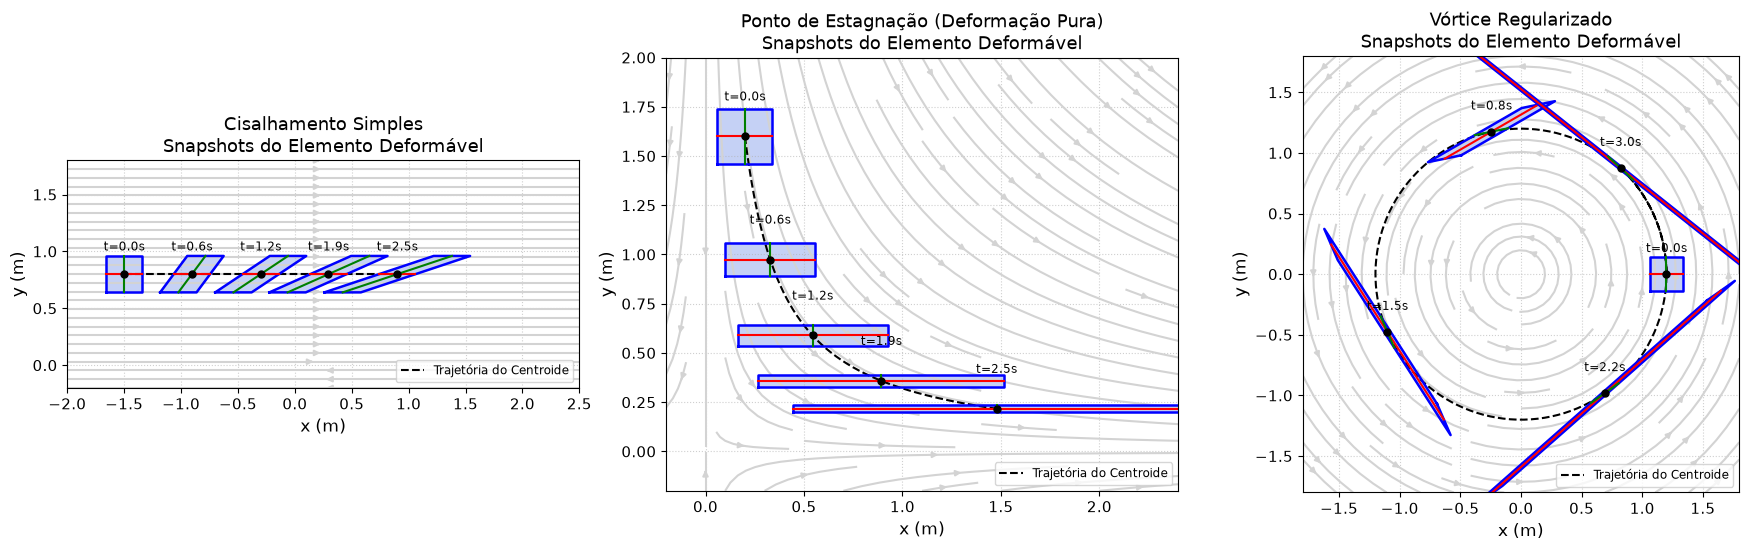

In [7]:
def calc_L_ponto(campo, x, y, t=0, h=1e-5):
    # Calcula matriz 2x2 do gradiente de velocidades L = grad(V)
    uxp, vxp = campo(x + h, y, t); uxm, vxm = campo(x - h, y, t)
    uyp, vyp = campo(x, y + h, t); uym, vym = campo(x, y - h, t)
    return np.array([[(uxp - uxm) / (2 * h), (uyp - uym) / (2 * h)],
                     [(vxp - vxm) / (2 * h), (vyp - vym) / (2 * h)]])

def simular_trajetoria_tensorial(campo, x0, y0, t_total=2.5, dt=0.01, mu=1e-3, p0=101325):
    # Simulação completa da partícula fluida deformável e seu histórico de tensores
    N = int(t_total / dt)
    t_hist = np.linspace(0, t_total, N + 1)
    x_hist = np.zeros((N + 1, 2))
    F_hist = np.zeros((N + 1, 2, 2))
    D_hist = np.zeros((N + 1, 2, 2))
    Omega_hist = np.zeros((N + 1, 2, 2))
    tau_hist = np.zeros((N + 1, 2, 2))
    sigma_hist = np.zeros((N + 1, 2, 2))
    theta_hist = np.zeros(N + 1)
    gamma_hist = np.zeros(N + 1)
    detF_hist = np.zeros(N + 1)
    
    x_hist[0] = [x0, y0]
    F_hist[0] = np.eye(2)
    detF_hist[0] = 1.0
    
    e1_0 = np.array([1.0, 0.0])
    e2_0 = np.array([0.0, 1.0])
    
    for n in range(N):
        tn = t_hist[n]
        xn = x_hist[n]
        Fn = F_hist[n]
        
        # RK4 acoplado para x_c e F
        k1_x = np.array(campo(xn[0], xn[1], tn))
        k1_L = calc_L_ponto(campo, xn[0], xn[1], tn)
        k1_F = k1_L @ Fn
        
        x2 = xn + 0.5 * dt * k1_x
        F2 = Fn + 0.5 * dt * k1_F
        t2 = tn + 0.5 * dt
        k2_x = np.array(campo(x2[0], x2[1], t2))
        k2_L = calc_L_ponto(campo, x2[0], x2[1], t2)
        k2_F = k2_L @ F2
        
        x3 = xn + 0.5 * dt * k2_x
        F3 = Fn + 0.5 * dt * k2_F
        t3 = tn + 0.5 * dt
        k3_x = np.array(campo(x3[0], x3[1], t3))
        k3_L = calc_L_ponto(campo, x3[0], x3[1], t3)
        k3_F = k3_L @ F3
        
        x4 = xn + dt * k3_x
        F4 = Fn + dt * k3_F
        t4 = tn + dt
        k4_x = np.array(campo(x4[0], x4[1], t4))
        k4_L = calc_L_ponto(campo, x4[0], x4[1], t4)
        k4_F = k4_L @ F4
        
        x_hist[n + 1] = xn + (dt / 6.0) * (k1_x + 2*k2_x + 2*k3_x + k4_x)
        F_hist[n + 1] = Fn + (dt / 6.0) * (k1_F + 2*k2_F + 2*k3_F + k4_F)
        
        # Tensores instantâneos em t_n
        Dn = 0.5 * (k1_L + k1_L.T)
        On = 0.5 * (k1_L - k1_L.T)
        D_hist[n] = Dn
        Omega_hist[n] = On
        tau_hist[n] = 2.0 * mu * Dn
        sigma_hist[n] = -p0 * np.eye(2) + tau_hist[n]
        
        # Decomposição polar F = R * U
        R, U = polar(Fn)
        theta_hist[n] = np.arctan2(R[1, 0], R[0, 0])
        detF_hist[n] = np.linalg.det(Fn)
        
        # Distorção angular entre as linhas materiais ortogonais originais
        e1 = Fn @ e1_0
        e2 = Fn @ e2_0
        cos_phi = np.clip(np.dot(e1, e2) / (np.linalg.norm(e1) * np.linalg.norm(e2)), -1.0, 1.0)
        gamma_hist[n] = np.pi/2 - np.arccos(cos_phi)

    # Último instante
    L_last = calc_L_ponto(campo, x_hist[-1, 0], x_hist[-1, 1], t_hist[-1])
    D_hist[-1] = 0.5 * (L_last + L_last.T)
    Omega_hist[-1] = 0.5 * (L_last - L_last.T)
    tau_hist[-1] = 2.0 * mu * D_hist[-1]
    sigma_hist[-1] = -p0 * np.eye(2) + tau_hist[-1]
    R_last, _ = polar(F_hist[-1])
    theta_hist[-1] = np.arctan2(R_last[1, 0], R_last[0, 0])
    detF_hist[-1] = np.linalg.det(F_hist[-1])
    e1 = F_hist[-1] @ e1_0
    e2 = F_hist[-1] @ e2_0
    cos_phi = np.clip(np.dot(e1, e2) / (np.linalg.norm(e1) * np.linalg.norm(e2)), -1.0, 1.0)
    gamma_hist[-1] = np.pi/2 - np.arccos(cos_phi)
    
    return {
        "t": t_hist, "x": x_hist, "F": F_hist, "D": D_hist,
        "Omega": Omega_hist, "tau": tau_hist, "sigma": sigma_hist,
        "theta": theta_hist, "gamma": gamma_hist, "detF": detF_hist
    }

# Simulação nos 3 regimes fundamentais
sim_cis = simular_trajetoria_tensorial(campo_cisalhamento, x0=-1.5, y0=0.8, t_total=2.5, dt=0.01)
sim_est = simular_trajetoria_tensorial(campo_estagnacao, x0=0.2, y0=1.6, t_total=2.5, dt=0.01)
sim_vor = simular_trajetoria_tensorial(campo_vortice, x0=1.2, y0=0.0, t_total=3.0, dt=0.01)

# Visualização da trajetória e deformação do elemento fluido em múltiplos snapshots
fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))
casos_sim = [
    (axs[0], campo_cisalhamento, sim_cis, "Cisalhamento Simples", (-2, 2.5), (-0.2, 1.8), 0.16),
    (axs[1], campo_estagnacao, sim_est, "Ponto de Estagnação (Deformação Pura)", (-0.2, 2.4), (-0.2, 2.0), 0.14),
    (axs[2], campo_vortice, sim_vor, "Vórtice Regularizado", (-1.8, 1.8), (-1.8, 1.8), 0.14)
]

for ax, campo, sim, titulo, lx, ly, s_tam in casos_sim:
    X, Y, U, V = gerar_grade(campo, lim_x=lx, lim_y=ly, n=35)
    ax.streamplot(X, Y, U, V, color="lightgray", density=0.9, arrowsize=0.8)
    
    # Trajetória do centroide
    ax.plot(sim["x"][:, 0], sim["x"][:, 1], "k--", lw=1.5, label="Trajetória do Centroide")
    
    # Desenho da partícula fluida deformada em 5 instantes de tempo
    indices_snaps = np.linspace(0, len(sim["t"]) - 1, 5, dtype=int)
    quad_ref = np.array([[-s_tam, -s_tam], [s_tam, -s_tam], [s_tam, s_tam], [-s_tam, s_tam], [-s_tam, -s_tam]])
    eixo_x_ref = np.array([[-s_tam, 0], [s_tam, 0]])
    eixo_y_ref = np.array([[0, -s_tam], [0, s_tam]])
    
    for idx in indices_snaps:
        xc = sim["x"][idx]
        Fn = sim["F"][idx]
        q_def = xc + quad_ref @ Fn.T
        ex_def = xc + eixo_x_ref @ Fn.T
        ey_def = xc + eixo_y_ref @ Fn.T
        
        ax.plot(q_def[:, 0], q_def[:, 1], "b-", lw=1.8)
        ax.fill(q_def[:, 0], q_def[:, 1], color="royalblue", alpha=0.3)
        ax.plot(ex_def[:, 0], ex_def[:, 1], "r-", lw=1.5)
        ax.plot(ey_def[:, 0], ey_def[:, 1], "g-", lw=1.5)
        ax.scatter([xc[0]], [xc[1]], color="black", s=25, zorder=5)
        ax.text(xc[0], xc[1] + s_tam * 1.3, f"t={sim['t'][idx]:.1f}s", fontsize=8.5, ha="center")
        
    ax.set_aspect("equal")
    ax.set_xlim(lx); ax.set_ylim(ly)
    ax.set(xlabel="x (m)", ylabel="y (m)", title=f"{titulo}\nSnapshots do Elemento Deformável")
    ax.legend(loc="lower right", fontsize=8.5)

plt.tight_layout()
plt.show()

### 5.6 Séries Temporais dos Tensores e Verificação Física

Abaixo traçamos a evolução temporal rigorosa das grandezas tensoriais ao longo da trajetória da partícula no escoamento de cisalhamento simples:
- **Taxas de deformação**: $D_{xx}(t)$, $D_{yy}(t)$, $D_{xy}(t)$.
- **Velocidade angular média**: $\Omega_z(t)$ vs. Vorticidade $\omega_z(t)$.
- **Tensão de cisalhamento viscosa**: $\tau_{xy}(t) = 2\mu D_{xy}$.
- **Rotação rígida finita $\theta(t)$ e Deformação angular $\gamma(t)$**.
- **Invariância de Volume**: Verificação numérica de que $\det(\mathbf{F}(t)) \equiv 1{,}0000$ e $\mathrm{tr}(\mathbf{D}(t)) \equiv 0{,}0000$ (conservação estrita de volume no fluido incompressível).

Verificação de Incompressibilidade: det(F) médio = 1.000000 (Desvio máx = 0.00e+00)
Distorção angular final após 2.5 s: gamma = 71.57°
Rotação de corpo rígido acumulada: theta = -56.31°


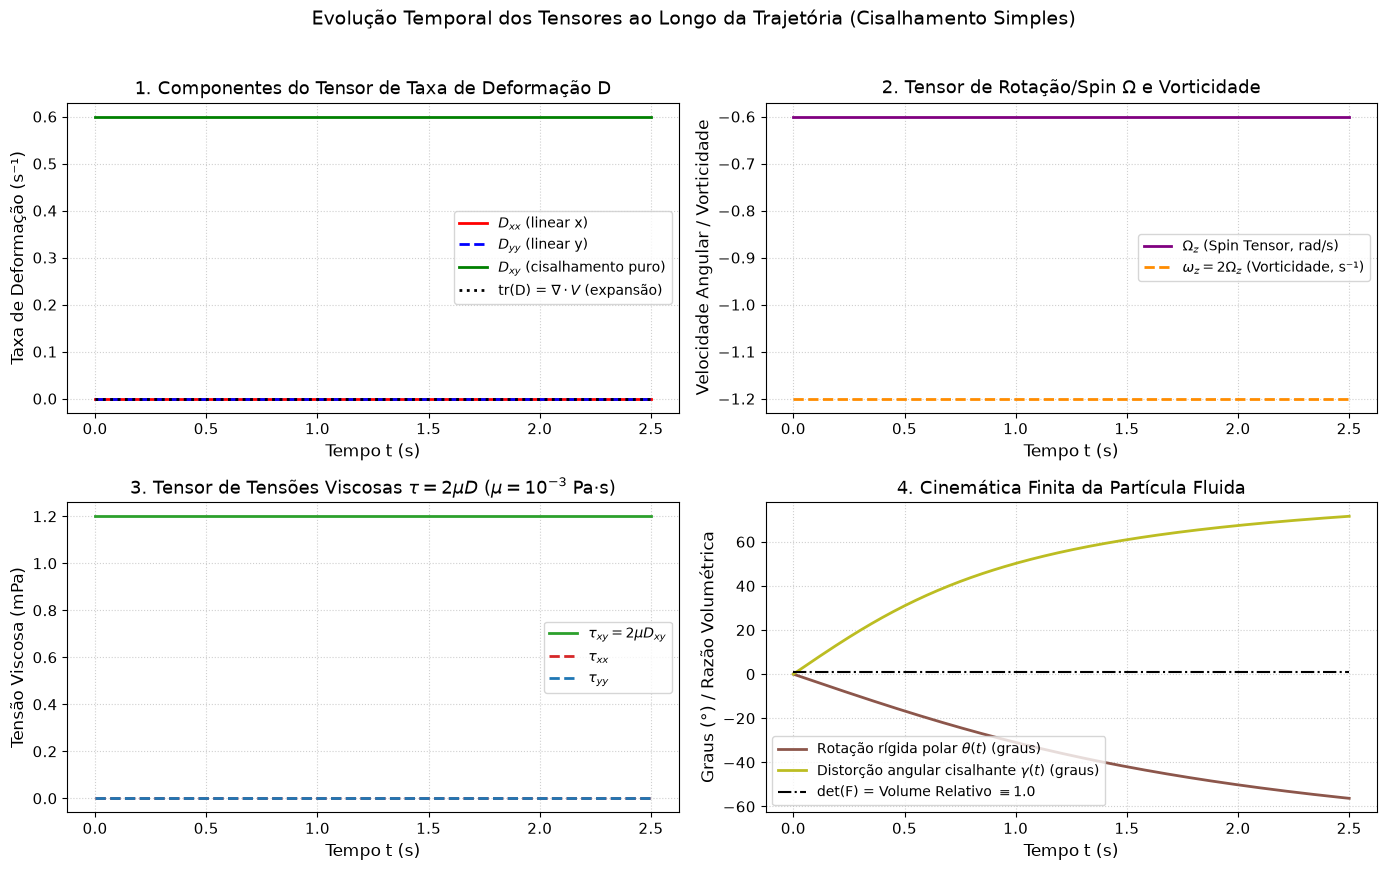

In [8]:
fig, axs = plt.subplots(2, 2, figsize=(14, 8.5))
t = sim_cis["t"]

# Subplot 1: Componentes da Taxa de Deformação D
axs[0, 0].plot(t, sim_cis["D"][:, 0, 0], "r-", lw=2, label="$D_{xx}$ (linear x)")
axs[0, 0].plot(t, sim_cis["D"][:, 1, 1], "b--", lw=2, label="$D_{yy}$ (linear y)")
axs[0, 0].plot(t, sim_cis["D"][:, 0, 1], "g-", lw=2, label="$D_{xy}$ (cisalhamento puro)")
axs[0, 0].plot(t, sim_cis["D"][:, 0, 0] + sim_cis["D"][:, 1, 1], "k:", lw=2, label="tr(D) = $\\nabla\\cdot V$ (expansão)")
axs[0, 0].set(xlabel="Tempo t (s)", ylabel="Taxa de Deformação (s⁻¹)", title="1. Componentes do Tensor de Taxa de Deformação D")
axs[0, 0].legend(loc="best")

# Subplot 2: Rotação do Tensor e Vorticidade
axs[0, 1].plot(t, sim_cis["Omega"][:, 1, 0], "purple", lw=2, label="$\\Omega_z$ (Spin Tensor, rad/s)")
axs[0, 1].plot(t, 2.0 * sim_cis["Omega"][:, 1, 0], "darkorange", lw=2, linestyle="--", label="$\\omega_z = 2\\Omega_z$ (Vorticidade, s⁻¹)")
axs[0, 1].set(xlabel="Tempo t (s)", ylabel="Velocidade Angular / Vorticidade", title="2. Tensor de Rotação/Spin $\\Omega$ e Vorticidade")
axs[0, 1].legend(loc="best")

# Subplot 3: Tensões Viscosas
axs[1, 0].plot(t, sim_cis["tau"][:, 0, 1] * 1000, "tab:green", lw=2, label="$\\tau_{xy} = 2\\mu D_{xy}$")
axs[1, 0].plot(t, sim_cis["tau"][:, 0, 0] * 1000, "tab:red", lw=2, linestyle="--", label="$\\tau_{xx}$")
axs[1, 0].plot(t, sim_cis["tau"][:, 1, 1] * 1000, "tab:blue", lw=2, linestyle="--", label="$\\tau_{yy}$")
axs[1, 0].set(xlabel="Tempo t (s)", ylabel="Tensão Viscosa (mPa)", title="3. Tensor de Tensões Viscosas $\\tau = 2\\mu D$ ($\mu = 10^{-3}$ Pa·s)")
axs[1, 0].legend(loc="best")

# Subplot 4: Rotação Rígida e Distorção Angular Acumuladas
theta_deg = np.degrees(sim_cis["theta"])
gamma_deg = np.degrees(sim_cis["gamma"])
axs[1, 1].plot(t, theta_deg, "tab:brown", lw=2, label="Rotação rígida polar $\\theta(t)$ (graus)")
axs[1, 1].plot(t, gamma_deg, "tab:olive", lw=2, label="Distorção angular cisalhante $\\gamma(t)$ (graus)")
axs[1, 1].plot(t, sim_cis["detF"], "k-.", lw=1.5, label="det(F) = Volume Relativo $\\equiv 1.0$")
axs[1, 1].set(xlabel="Tempo t (s)", ylabel="Graus (°) / Razão Volumétrica", title="4. Cinemática Finita da Partícula Fluida")
axs[1, 1].legend(loc="best")

plt.suptitle("Evolução Temporal dos Tensores ao Longo da Trajetória (Cisalhamento Simples)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print(f"Verificação de Incompressibilidade: det(F) médio = {np.mean(sim_cis['detF']):.6f} (Desvio máx = {np.max(np.abs(sim_cis['detF'] - 1.0)):.2e})")
print(f"Distorção angular final após {t[-1]:.1f} s: gamma = {gamma_deg[-1]:.2f}°")
print(f"Rotação de corpo rígido acumulada: theta = {theta_deg[-1]:.2f}°")

### 5.7 Animação Interativa do Movimento da Partícula Fluida

Para consolidar visualmente a cinemática tensorial contínua, a célula abaixo carrega e renderiza a animação dinâmica `animacao_particula_tensores.gif`, onde o elemento de fluido translada, sofre rotação polar e distorção angular em tempo real, acompanhado de telemetria dos tensores instantâneos:

Exibindo animação da partícula fluida deformável (Códigos/animacao_particula_tensores.gif):
<IPython.core.display.Image object>



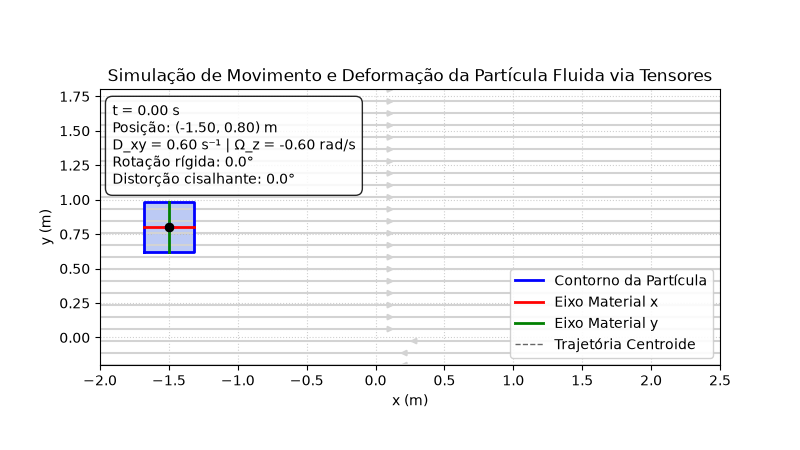

In [9]:
# Carrega e exibe a animação gerada da partícula fluida deformável
candidatos_gif = [
    "animacao_particula_tensores.gif",
    "Códigos/animacao_particula_tensores.gif",
    os.path.join(os.path.dirname(__file__) if "__file__" in locals() else ".", "animacao_particula_tensores.gif"),
    os.path.join(os.path.dirname(__file__) if "__file__" in locals() else ".", "Códigos", "animacao_particula_tensores.gif")
]
gif_path = next((p for p in candidatos_gif if os.path.exists(p)), None)
if gif_path:
    print(f"Exibindo animação da partícula fluida deformável ({gif_path}):")
    display(Image(filename=gif_path))
else:
    print("Arquivo animacao_particula_tensores.gif não encontrado.")

## 6. Pressão em um Fluido Estático (Hidrostática)

Com o eixo $z$ positivo para cima e gravidade $\mathbf{g} = -g\mathbf{k}$, a condição de repouso mecânico impõe que a taxa de deformação seja nula ($\mathbf{D} = \mathbf{0}$).
Consequentemente, o tensor de tensões reduz-se à pressão isotrópica hidrostática pura:
$$
\boldsymbol{\sigma} = -p\mathbf{I} = \begin{bmatrix} -p & 0 & 0 \\ 0 & -p & 0 \\ 0 & 0 & -p \end{bmatrix}
$$
Não há qualquer tensão cisalhante em um fluido em repouso ($\boldsymbol{\tau} = \mathbf{0}$).
A equação de equilíbrio de quantidade de movimento é:
$$
\nabla p = \rho\mathbf{g} \implies \frac{dp}{dz} = -\rho g \implies p(h) = p_0 + \rho g h
$$
Onde $h$ é a profundidade medida a partir da superfície livre.

Na profundidade de 5 m:  p_man = 49.05 kPa | p_abs = 150.38 kPa
Na profundidade de 12 m: p_man = 117.72 kPa | p_abs = 219.04 kPa


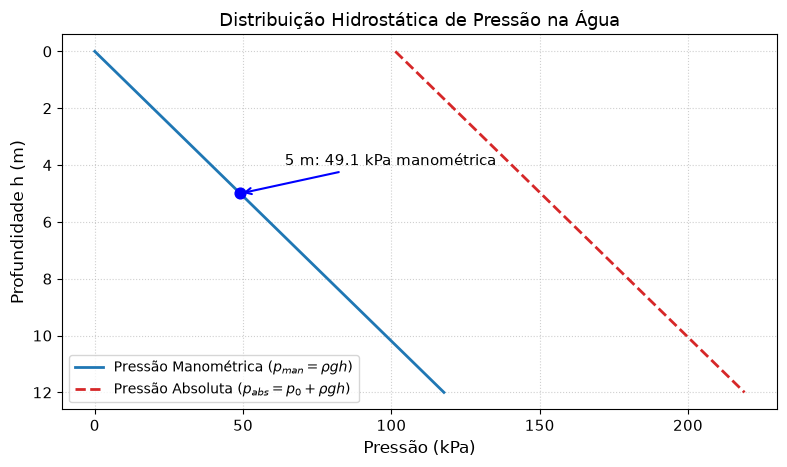

In [10]:
rho_agua = 1000.0   # kg/m³
g = 9.81            # m/s²
patm = 101325.0     # Pa

h = np.linspace(0, 12, 200)
p_manometrica = rho_agua * g * h
p_absoluta = patm + p_manometrica

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(p_manometrica / 1000.0, h, "tab:blue", lw=2, label=r"Pressão Manométrica ($p_{man} = \rho g h$)")
ax.plot(p_absoluta / 1000.0, h, "tab:red", lw=2, linestyle="--", label=r"Pressão Absoluta ($p_{abs} = p_0 + \rho g h$)")

ax.scatter([rho_agua * g * 5.0 / 1000.0], [5.0], color="blue", s=60, zorder=5)
ax.annotate("5 m: 49.1 kPa manométrica", xy=(rho_agua * g * 5.0 / 1000.0, 5.0),
            xytext=(rho_agua * g * 5.0 / 1000.0 + 15, 4.0),
            arrowprops=dict(arrowstyle="->", color="blue", lw=1.5))

ax.invert_yaxis()
ax.set(xlabel="Pressão (kPa)", ylabel="Profundidade h (m)", title="Distribuição Hidrostática de Pressão na Água")
ax.legend(loc="lower left")
plt.show()

print(f"Na profundidade de 5 m:  p_man = {rho_agua*g*5/1000:.2f} kPa | p_abs = {(patm+rho_agua*g*5)/1000:.2f} kPa")
print(f"Na profundidade de 12 m: p_man = {p_manometrica[-1]/1000:.2f} kPa | p_abs = {p_absoluta[-1]/1000:.2f} kPa")

## 7. Tensão de Cisalhamento e Escoamentos Viscosos: Couette e Poiseuille

Para um escoamento unidimensional de fluido newtoniano $u = u(y)$, a única componente não-nula do tensor de tensões viscosas é:
$$
\tau_{xy} = 2\mu D_{xy} = \mu \frac{du}{dy}
$$
1. **Escoamento de Couette Plano**: Placa superior móvel com velocidade $U_{\text{top}}$ e gradiente de pressão nulo ($\frac{dp}{dx} = 0$):
$$
u(y) = U_{\text{top}}\frac{y}{H}, \qquad \tau_{xy} = \mu\frac{U_{\text{top}}}{H} = \text{constante}
$$
2. **Escoamento de Poiseuille Plano**: Ambas as placas fixas sob gradiente de pressão constante $\frac{dp}{dx} < 0$:
$$
u(y) = -\frac{1}{2\mu}\frac{dp}{dx} y(H - y), \qquad \tau_{xy}(y) = \mu\frac{du}{dy} = -\frac{dp}{dx}\left(\frac{H}{2} - y\right)
$$
A tensão cisalhante em Poiseuille varia linearmente com $y$, anulando-se na linha de centro ($y = H/2$) e atingindo valor máximo absoluto nas paredes.

Vazão específica Couette:    q = 0.006000 m²/s  (analítico: Utop*H/2 = 0.006000)
Vazão específica Poiseuille: q = 0.079999 m²/s  (analítico: -dpdx*H³/(12*mu) = 0.080000)


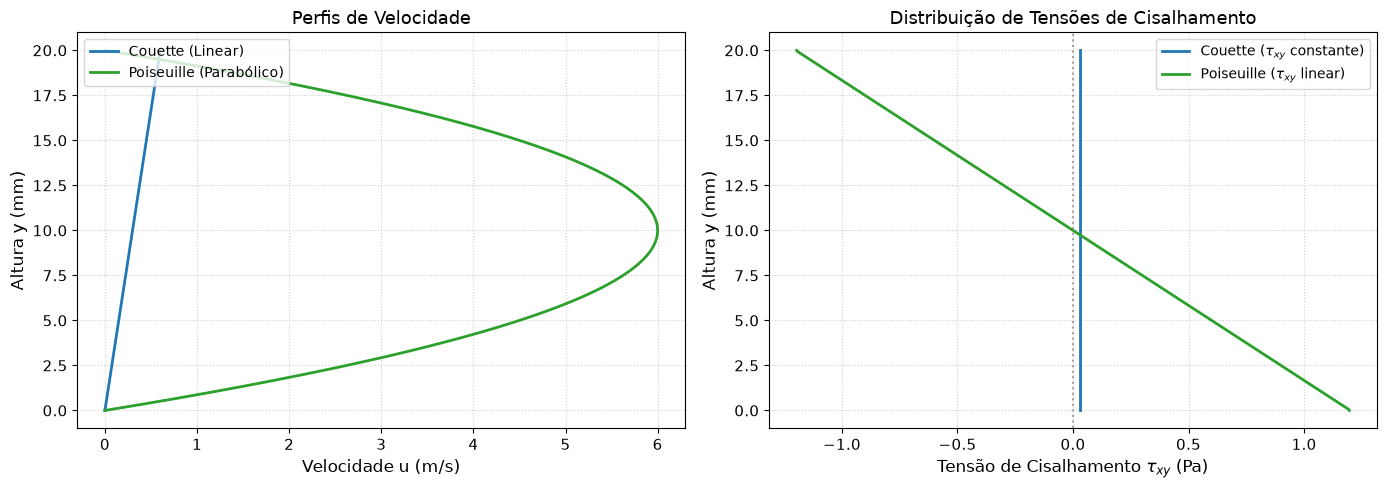

In [11]:
H = 0.02          # Espaçamento entre placas: 20 mm
Utop = 0.6        # Velocidade da placa móvel: 0.6 m/s
mu = 1e-3         # Viscosidade dinâmica: 1 mPa.s (água)
dpdx = -120.0     # Gradiente de pressão imposto: -120 Pa/m

y = np.linspace(0, H, 300)
u_couette = Utop * y / H
u_poiseuille = -(dpdx) / (2.0 * mu) * y * (H - y)

tau_couette = mu * np.gradient(u_couette, y)
tau_poiseuille = mu * np.gradient(u_poiseuille, y)

fig, axs = plt.subplots(1, 2, figsize=(14, 5.0))

# Perfis de Velocidade
axs[0].plot(u_couette, y * 1000.0, "tab:blue", lw=2, label="Couette (Linear)")
axs[0].plot(u_poiseuille, y * 1000.0, "tab:green", lw=2, label="Poiseuille (Parabólico)")
axs[0].set(xlabel="Velocidade u (m/s)", ylabel="Altura y (mm)", title="Perfis de Velocidade")
axs[0].legend(loc="upper left")

# Perfis de Tensão Cisalhante
axs[1].plot(tau_couette, y * 1000.0, "tab:blue", lw=2, label=r"Couette ($\tau_{xy}$ constante)")
axs[1].plot(tau_poiseuille, y * 1000.0, "tab:green", lw=2, label=r"Poiseuille ($\tau_{xy}$ linear)")
axs[1].axvline(0, color="gray", linestyle=":", alpha=0.7)
axs[1].set(xlabel=r"Tensão de Cisalhamento $\tau_{xy}$ (Pa)", ylabel="Altura y (mm)", title="Distribuição de Tensões de Cisalhamento")
axs[1].legend(loc="upper right")

plt.show()

# Vazão volumétrica por unidade de largura: q = integral(u dy)
q_couette = float(np.trapezoid(u_couette, y))
q_poiseuille = float(np.trapezoid(u_poiseuille, y))
print(f"Vazão específica Couette:    q = {q_couette:.6f} m²/s  (analítico: Utop*H/2 = {Utop*H/2:.6f})")
print(f"Vazão específica Poiseuille: q = {q_poiseuille:.6f} m²/s  (analítico: -dpdx*H³/(12*mu) = {-dpdx*H**3/(12*mu):.6f})")

## 8. Conservação da Massa (Continuidade Diferencial)

A conservação da massa para um volume de controle diferencial é dada pela equação da continuidade:
$$
\frac{\partial\rho}{\partial t} + \nabla\cdot(\rho\mathbf{V}) = 0
$$
Para escoamento **incompressível** ($\rho = \text{constante}$):
$$
\nabla\cdot\mathbf{V} = \frac{\partial u}{\partial x} + \frac{\partial v}{\partial y} = 0 \iff \mathrm{tr}(\mathbf{D}) = 0
$$
O divergente mede geometricamente a taxa relativa de expansão ou compressão volumétrica local de uma partícula de fluido.
- $\nabla\cdot\mathbf{V} = 0$: O volume da partícula preserva-se rigorosamente ($\det(\mathbf{F}) = 1$).
- $\nabla\cdot\mathbf{V} > 0$: O volume da partícula está expandindo localmente.

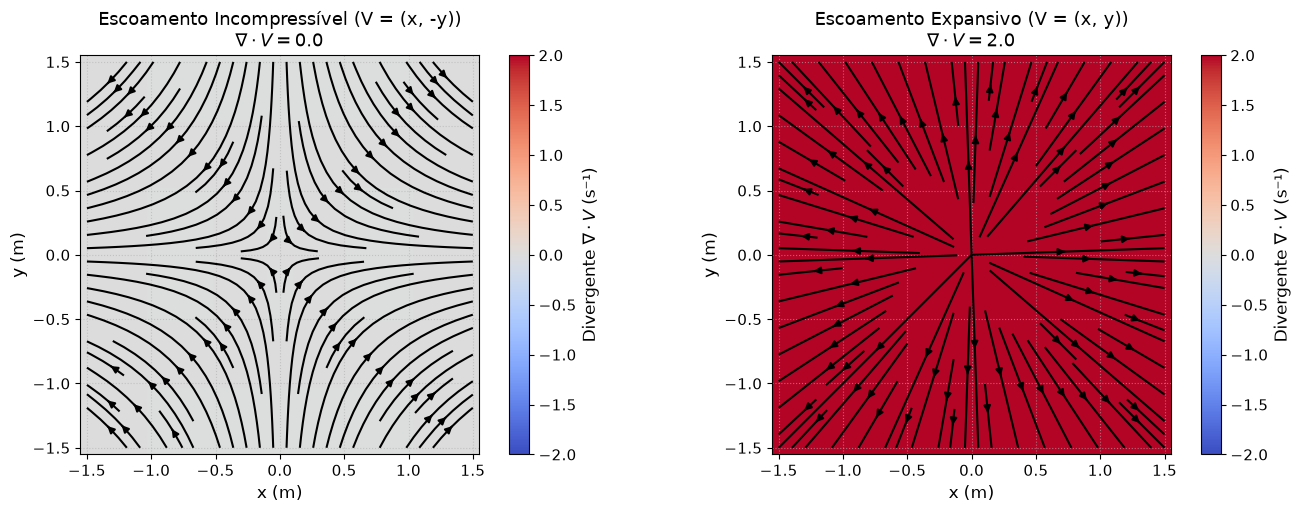

In [12]:
def divergente(campo, X, Y, h=1e-5):
    # Calcula numericamente o divergente div(V) = du/dx + dv/dy
    Uxp, _ = campo(X + h, Y); Uxm, _ = campo(X - h, Y)
    _, Vyp = campo(X, Y + h); _, Vym = campo(X, Y - h)
    return (Uxp - Uxm) / (2 * h) + (Vyp - Vym) / (2 * h)

def campo_incompressivel(x, y):
    return x, -y

def campo_expansivo(x, y):
    return x, y

X, Y = np.meshgrid(np.linspace(-1.5, 1.5, 30), np.linspace(-1.5, 1.5, 30))
fig, axs = plt.subplots(1, 2, figsize=(14, 5.2))

casos_div = [
    (axs[0], campo_incompressivel, "Escoamento Incompressível (V = (x, -y))"),
    (axs[1], campo_expansivo, "Escoamento Expansivo (V = (x, y))")
]

for ax, campo, tit in casos_div:
    U, V = campo(X, Y)
    D = divergente(campo, X, Y)
    im = ax.pcolormesh(X, Y, D, shading="auto", cmap="coolwarm", vmin=-2, vmax=2)
    ax.streamplot(X, Y, U, V, color="black", density=1.0)
    ax.set_aspect("equal")
    ax.set(xlabel="x (m)", ylabel="y (m)", title=f"{tit}\n" + r"$\nabla\cdot V = $" + f"{D.mean():.1f}")
    fig.colorbar(im, ax=ax, label=r"Divergente $\nabla\cdot V$ (s⁻¹)")

plt.show()

## 9. Quantidade de Movimento: Navier–Stokes e Euler

A equação fundamental da dinâmica dos fluidos newtonianos incompressíveis é a **Equação de Navier-Stokes**:
$$
\rho\left(\frac{\partial\mathbf{V}}{\partial t} + (\mathbf{V}\cdot\nabla)\mathbf{V}\right) = \nabla\cdot\boldsymbol{\sigma} + \rho\mathbf{g} = -\nabla p + \mu\nabla^2\mathbf{V} + \rho\mathbf{g}
$$
- Se $\mu = 0$ (viscosidade desprezível), anulam-se as tensões de cisalhamento ($\boldsymbol{\tau} = \mathbf{0}$) e obtemos as **Equações de Euler**:
$$
\rho\left(\frac{\partial\mathbf{V}}{\partial t} + (\mathbf{V}\cdot\nabla)\mathbf{V}\right) = -\nabla p + \rho\mathbf{g}
$$

Abaixo resolvemos computacionalmente o problema de difusão de quantidade de movimento 1D (1º problema de Stokes / partida de Couette):
$$
\frac{\partial u}{\partial t} = \nu \frac{\partial^2 u}{\partial y^2}
$$
Com condição de contorno de não-deslizamento: $u(0, t) = 0$ e $u(H, t) = U_0$ para $t > 0$, com fluido inicialmente em repouso $u(y, 0) = 0$.

Passo de tempo: dt = 0.00175 s
Número de Fourier difusivo: Fo = nu * dt / dy² = 0.350 <= 0.5 (Estável)


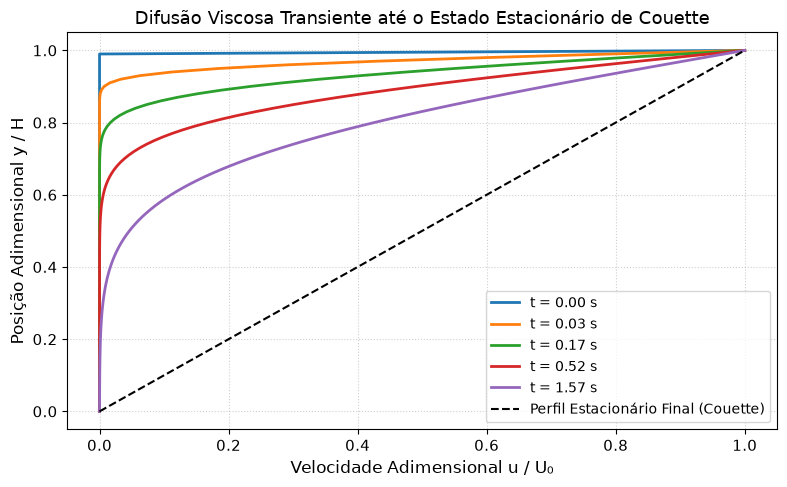

In [13]:
H = 1.0           # Espessura total do canal (m)
N = 101           # Número de nós da malha espacial
nu = 0.02         # Viscosidade cinemática (m²/s)

y = np.linspace(0, H, N)
dy = y[1] - y[0]
dt = 0.35 * dy**2 / nu   # Critério de estabilidade FTCS: Fourier = nu * dt / dy^2 <= 0.5

u = np.zeros(N)
u[-1] = 1.0       # Velocidade imposta na placa superior
snaps = [(0.0, u.copy())]

# Marcha no tempo via diferenças finitas explícitas
for n in range(1, 900):
    u_old = u.copy()
    u[1:-1] = u_old[1:-1] + nu * dt / dy**2 * (u_old[2:] - 2*u_old[1:-1] + u_old[:-2])
    u[0] = 0.0
    u[-1] = 1.0
    if n in [20, 100, 300, 899]:
        snaps.append((n * dt, u.copy()))

fig, ax = plt.subplots(figsize=(8, 5.0))
for t_val, u_snap in snaps:
    ax.plot(u_snap, y, lw=2, label=f"t = {t_val:.2f} s")

ax.plot(y, y, "k--", lw=1.5, label="Perfil Estacionário Final (Couette)")
ax.set(xlabel="Velocidade Adimensional u / U₀", ylabel="Posição Adimensional y / H",
       title="Difusão Viscosa Transiente até o Estado Estacionário de Couette")
ax.legend(loc="lower right")
plt.show()

print(f"Passo de tempo: dt = {dt:.5f} s")
print(f"Número de Fourier difusivo: Fo = nu * dt / dy² = {nu * dt / dy**2:.3f} <= 0.5 (Estável)")

## 10. Síntese Conceitual e Exercícios Resolvidos

### Mapa Conceitual da Mecânica dos Fluidos
```
                 CAMPO DE VELOCIDADES V(x, y, z, t)
                                 │
     ┌───────────────────────────┼───────────────────────────┐
     ▼                           ▼                           ▼
DERIVADA SUBSTANCIAL     TENSOR GRADIENTE            CONSERVAÇÃO DA MASSA
    DV/Dt =                     L = ∇V                     ∂ρ/∂t + ∇·(ρV) = 0
 ∂V/∂t + (V·∇)V                  │                           │
(Local + Convectiva)     ┌───────┴───────┐                   ▼
                         ▼               ▼            Fluido Incompressível:
                  TAXA DEFORMAÇÃO     ROTAÇÃO / SPIN   ∇·V = tr(D) = 0
                  D = 1/2(L + L^T)   Ω = 1/2(L - L^T)
                         │               │
                         ▼               ▼
                  TENSÕES CAUCHY    VORTICIDADE
                  σ = -pI + 2μD      ω = 2 Ω_z
                         │
                         ▼
                QUANTIDADE DE MOVIMENTO (NAVIER-STOKES)
                ρ DV/Dt = ∇·σ + ρg = -∇p + μ∇²V + ρg
```

---

### Questões Analíticas e Conceituais

1. **Diferença entre Aceleração Local e Convectiva**:
   - *Local ($\partial\mathbf{V}/\partial t$)*: Taxa de variação temporal da velocidade observada em um ponto fixo do espaço. Nula em escoamentos permanentes.
   - *Convectiva ($(\mathbf{V}\cdot\nabla)\mathbf{V}$)*: Taxa de variação associada à mudança de posição da partícula fluida através de regiões com diferentes velocidades.

2. **Significado Físico dos Tensores $\mathbf{D}$ e $\mathbf{\Omega}$**:
   - $\mathbf{D}$: Mede as taxas de distorção do elemento fluido. Os termos diagonais $D_{xx}, D_{yy}$ representam deformação linear (alongamento/encurtamento), enquanto os termos fora da diagonal $D_{xy}$ representam metade da taxa de deformação angular (cisalhamento puro). Seu traço $\mathrm{tr}(\mathbf{D}) = \nabla\cdot\mathbf{V}$ é a taxa de dilatação volumétrica.
   - $\mathbf{\Omega}$: Mede a rotação de corpo rígido instantânea pura da partícula fluida sem qualquer mudança de forma ou ângulo, com velocidade angular $\Omega_z = \frac{1}{2}\omega_z$.

3. **Cálculo da Vorticidade e Tensores para $\mathbf{V} = (a y, 0)$**:
   - $\mathbf{L} = \begin{bmatrix} 0 & a \\ 0 & 0 \end{bmatrix}$
   - $\mathbf{D} = \begin{bmatrix} 0 & a/2 \\ a/2 & 0 \end{bmatrix} \implies \dot{\gamma}_{xy} = a$
   - $\mathbf{\Omega} = \begin{bmatrix} 0 & a/2 \\ -a/2 & 0 \end{bmatrix} \implies \Omega_z = -a/2 \implies \omega_z = -a$.

4. **Por que um escoamento permanente ainda pode apresentar aceleração?**:
   - Porque as linhas de corrente podem convergir, divergir ou curvar-se no espaço. Mesmo com $\partial\mathbf{V}/\partial t = 0$, o termo convectivo $(\mathbf{V}\cdot\nabla)\mathbf{V}$ pode ser não-nulo (ex: bocal convergente ou escoamento circular).

5. **Pressão Manométrica a 5 m de Profundidade na Água**:
   - $p_{\text{man}} = \rho g h = 1000 \times 9{,}81 \times 5 = 49{,}05\text{ kPa}$.

6. **Verificação de Incompressibilidade de $\mathbf{V} = (x, -y)$**:
   - $\nabla\cdot\mathbf{V} = \frac{\partial x}{\partial x} + \frac{\partial (-y)}{\partial y} = 1 - 1 = 0 \implies \mathrm{tr}(\mathbf{D}) = 0$. Logo, o campo é perfeitamente incompressível.

7. **Relação entre o Tensor de Tensões de Cauchy $\boldsymbol{\sigma}$ e a Equação de Navier-Stokes**:
   - A equação da quantidade de movimento é $\rho \frac{D\mathbf{V}}{Dt} = \nabla\cdot\boldsymbol{\sigma} + \rho\mathbf{g}$. Substituindo a lei constitutiva newtoniana $\boldsymbol{\sigma} = -p\mathbf{I} + 2\mu\mathbf{D}$, a divergência do tensor produz $\nabla\cdot\boldsymbol{\sigma} = -\nabla p + \mu\nabla^2\mathbf{V}$, resultando diretamente em Navier-Stokes.

8. **O que ocorre com Navier-Stokes quando a viscosidade é nula ($\mu = 0$)?**:
   - O tensor de tensões viscosas anula-se ($\boldsymbol{\tau} = \mathbf{0}$), de modo que o tensor de tensões reduz-se à pressão hidrostática pura $\boldsymbol{\sigma} = -p\mathbf{I}$. Desaparece o termo difusivo laplaciano $\mu\nabla^2\mathbf{V}$, obtendo-se as **Equações de Euler** para fluidos não-viscosos.